# Chapter 5: the operations KPI dashboard

Reports the same closed cases under two definitions of cycle time: the analyst's (first touch to closure) and the customer's (claim to closure). Reads `ops_log.csv`, generated by `make_ops_log.py`. All data are synthetic and every number is illustrative.

## Listing 5.1: load the log and derive the intervals

In [1]:
import numpy as np
import pandas as pd
TIMES = ["claim_received_at", "case_created_at", "first_touch_at", "decision_at", "closed_at"]
log = pd.read_csv("ops_log.csv", parse_dates=TIMES)
def days(start, end):
    return (log[end] - log[start]).dt.total_seconds() / 86400
log["intake_lag"] = days("claim_received_at", "case_created_at")
log["queue_wait"] = days("case_created_at", "first_touch_at")
log["work_elapsed"] = days("first_touch_at", "decision_at")
log["closing_lag"] = days("decision_at", "closed_at")
log["analyst_cycle"] = days("first_touch_at", "closed_at")
log["claim_cycle"] = days("claim_received_at", "closed_at")

## Listing 5.2: percentiles under two definitions and the ten-business-day flag

In [2]:
# second notebook cell; Listing 5.1 has already run
def pctiles(series):
    return series.quantile([0.5, 0.9, 0.95]).round(1).tolist()
received = log["claim_received_at"].dt.normalize().values.astype("datetime64[D]")
log["due_date"] = pd.to_datetime(np.busday_offset(received, 10, roll="backward"))
log["breached"] = log["decision_at"].dt.normalize() > log["due_date"]
report = pd.DataFrame({"percentile": ["p50", "p90", "p95"],
                       "analyst_view": pctiles(log["analyst_cycle"]),
                       "claim_view": pctiles(log["claim_cycle"])})
print(report.to_string(index=False))
print("share past the 10-business-day mark:", round(log["breached"].mean(), 3))

percentile  analyst_view  claim_view
       p50           2.2         6.4
       p90           4.9        12.3
       p95           5.9        14.8
share past the 10-business-day mark: 0.048


## Table 5.6: headline indicators under two definitions

In [3]:
mean_wait = log["queue_wait"].mean()
table_5_6 = pd.DataFrame({
    "Indicator": ["Median cycle time", "90th percentile", "95th percentile",
                  "Decisions after 10 business days", "Mean queue wait"],
    "Analyst view": [f"{v} days" for v in pctiles(log["analyst_cycle"])]
                    + ["Cannot be computed", "Not visible"],
    "Claim view": [f"{v} days" for v in pctiles(log["claim_cycle"])]
                  + [f"{log['breached'].mean():.1%}",
                     f"{mean_wait:.1f} days ({mean_wait / log['claim_cycle'].mean():.0%} of the mean cycle)"],
})
print(f"{len(log):,} closed cases")
table_5_6

5,000 closed cases


,Indicator,Analyst view,Claim view
0,Median cycle time,2.2 days,6.4 days
1,90th percentile,4.9 days,12.3 days
2,95th percentile,5.9 days,14.8 days
3,Decisions after 10 business days,Cannot be computed,4.8%
4,Mean queue wait,Not visible,4.3 days (60% of the mean cycle)


## Two further findings: intake lag by channel and the surge period

In [4]:
from datetime import timedelta

intake_hours = (log.groupby("channel")["intake_lag"].mean() * 24).round(1)
print("mean intake lag, hours:")
print(intake_hours.sort_values().to_string())

cut = log["claim_received_at"].max().normalize() - timedelta(days=20)
surge = log["claim_received_at"] >= cut
print(f"\nclaims received from {cut:%Y-%m-%d} (final three weeks): {surge.sum():,}")
print("breach rate, final three weeks:", round(log.loc[surge, "breached"].mean(), 3))
print("breach rate, earlier:          ", round(log.loc[~surge, "breached"].mean(), 3))
print("mean queue wait, final three weeks vs earlier:",
      round(log.loc[surge, "queue_wait"].mean(), 1), "vs", round(log.loc[~surge, "queue_wait"].mean(), 1))

mean intake lag, hours:
channel
app        0.0
web        0.3
phone     13.1
branch    13.3

claims received from 2026-03-09 (final three weeks): 1,383
breach rate, final three weeks: 0.066
breach rate, earlier:           0.041
mean queue wait, final three weeks vs earlier: 4.8 vs 4.1


## Figure 5.5: the dashboard on the synthetic log

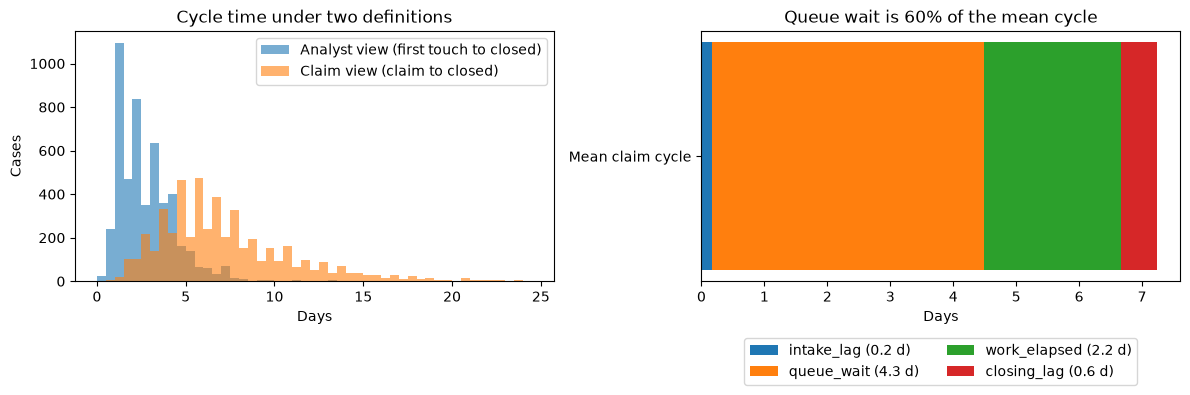

In [5]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.arange(0, 25, 0.5)
ax1.hist(log["analyst_cycle"], bins=bins, alpha=0.6, label="Analyst view (first touch to closed)")
ax1.hist(log["claim_cycle"], bins=bins, alpha=0.6, label="Claim view (claim to closed)")
ax1.set_xlabel("Days")
ax1.set_ylabel("Cases")
ax1.set_title("Cycle time under two definitions")
ax1.legend()
parts = log[["intake_lag", "queue_wait", "work_elapsed", "closing_lag"]].mean()
left = 0.0
for name, value in parts.items():
    ax2.barh(["Mean claim cycle"], [value], left=left, label=f"{name} ({value:.1f} d)")
    left += value
ax2.set_xlabel("Days")
ax2.set_title(f"Queue wait is {parts['queue_wait'] / parts.sum():.0%} of the mean cycle")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
fig.savefig("fig_5_5_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()

## Worked example: one claim, two stopwatches (Figure 5.2)

A claim made at 6:40 p.m. on a Friday, touched at 9:15 on Tuesday, decided at 10:05 and closed at 2:30 p.m.

In [6]:
ex = pd.Series({"claim_received_at": pd.Timestamp("2026-03-06 18:40"),
                "case_created_at": pd.Timestamp("2026-03-06 18:41"),
                "first_touch_at": pd.Timestamp("2026-03-10 09:15"),
                "decision_at": pd.Timestamp("2026-03-10 10:05"),
                "closed_at": pd.Timestamp("2026-03-10 14:30")})
print("analyst view:", ex["closed_at"] - ex["first_touch_at"])
print("claim view:  ", ex["closed_at"] - ex["claim_received_at"])
print("queue wait:  ", ex["first_touch_at"] - ex["case_created_at"])
used = np.busday_count(ex["claim_received_at"].date(), ex["decision_at"].date())
print("business day of the decision:", used, "of 10")

analyst view: 0 days 05:15:00
claim view:   3 days 19:50:00
queue wait:   3 days 14:34:00
business day of the decision: 2 of 10


## Capacity: Little's Law, the occupancy curve and Table 5.4

average 7 days from claim to closure -> 13,808 cases in flight
average 5 days from claim to closure -> 9,863 cases in flight
difference: 3,945 cases
hours of work: 480,000


,Target occupancy,Analysts needed,Average wait (x handling time)
0,75%,400,3.0
1,85%,353,5.7
2,95%,316,19.0


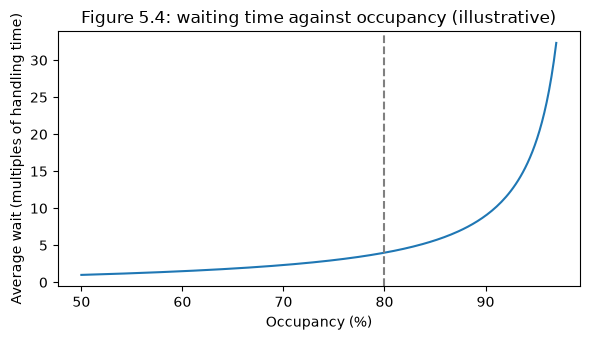

backlog after a 21-business-day month at +5% arrivals: 2,100 cases


In [7]:
per_day = 720_000 / 365
for w in (7, 5):
    print(f"average {w} days from claim to closure -> {per_day * w:,.0f} cases in flight")
print(f"difference: {per_day * 2:,.0f} cases")

hours_needed = 720_000 * 40 / 60
table_5_4 = pd.DataFrame({"Target occupancy": ["75%", "85%", "95%"],
                          "Analysts needed": [round(hours_needed / 1_600 / r) for r in (0.75, 0.85, 0.95)],
                          "Average wait (x handling time)": [round(r / (1 - r), 1) for r in (0.75, 0.85, 0.95)]})
print(f"hours of work: {hours_needed:,.0f}")
display(table_5_4)

rho = np.linspace(0.5, 0.97, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rho * 100, rho / (1 - rho))
ax.axvline(80, ls="--", color="grey")
ax.set_xlabel("Occupancy (%)")
ax.set_ylabel("Average wait (multiples of handling time)")
ax.set_title("Figure 5.4: waiting time against occupancy (illustrative)")
fig.tight_layout()
plt.show()

backlog = (2_100 - 2_000) * 21
print(f"backlog after a 21-business-day month at +5% arrivals: {backlog:,} cases")

## Quality review sample size

In [8]:
def sample_size(p=0.10, e=0.03, z=1.96):
    return int(np.ceil(z**2 * p * (1 - p) / e**2))
print("p=10%, e=3pts, 95% confidence:", sample_size())
print("p=10%, e=2pts, 95% confidence:", sample_size(e=0.02))

p=10%, e=3pts, 95% confidence: 385
p=10%, e=2pts, 95% confidence: 865
